In [10]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import anndata as ad
import numpy as np
import os
import matplotlib as mpl
from datetime import datetime
import seaborn as sns
from matplotlib import pyplot as plt
import harmonypy as hm

# For cleaner output
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Define the directory containing the sample directories
base_dir = "/scratch/svc_td_regene/eye_retinopathy/spatial_data/"
# Date
date = datetime.today().strftime('%Y%m%d')
date

'20261119'

In [4]:
def filter_spots(data, name, verbose=True):
    n_initial = data.shape[0]

    # MT pct
    data.var['mt'] = data.var_names.str.startswith('MT-')
    sc.pp.calculate_qc_metrics(
        data,
        qc_vars=['mt'],
        percent_top=None,
        log1p=False,
        inplace=True
    )

    # Filter cells with more than 20 % MT
    data = data[data.obs['pct_counts_mt'] < 20, :].copy()

    # Spot filtering for more than 300 genes and 600 counts
    sc.pp.filter_cells(data, min_counts=600)
    sc.pp.filter_cells(data, min_genes=300)

    # genes that appear in at least 3 cells
    sc.pp.filter_genes(data, min_cells=3)

    n_removed = n_initial - data.shape[0]
    if verbose:
        print(f'{name}: Filtered out {n_removed} cells.')
    return data

In [5]:
# Utility function for when loading in spatial slide information that haven't been normalized
def norm_and_log(adata):
    if "log1p" in adata.layers:
        print(f"Data is already transformed and has the log1p layer. Returning the data unmodified.")
        return adata
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adata.layers['log1p'] = adata.X.copy()
    return adata

In [6]:
samples = ['human_eye_1_rerun','human_eye_2']

adata_dict = {}

for sample in samples:
    adata = sq.read.visium(base_dir + sample)
    adata.obs['sample'] = sample
    adata = filter_spots(adata, sample)
    adata.obs.index = sample + '_' + adata.obs.index
    adata.var_names_make_unique()
    adata_dict[sample] = adata.copy()

adata_dict

human_eye_1_rerun: Filtered out 85 cells.
human_eye_2: Filtered out 475 cells.


{'human_eye_1_rerun': AnnData object with n_obs × n_vars = 387 × 12763
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_counts', 'n_genes'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
     uns: 'spatial'
     obsm: 'spatial',
 'human_eye_2': AnnData object with n_obs × n_vars = 1077 × 13809
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_counts', 'n_genes'
     var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
     uns: 'spatial'
     obsm: 'spatial'}

In [6]:
adata_concat = ad.concat(adata_dict, join='inner')
adata_concat.raw = adata_concat.copy()

sc.pp.normalize_total(adata_concat, target_sum=1e4)

sc.pp.log1p(adata_concat)

# save log1p
adata_concat.layers['log1p'] = adata_concat.X.copy()

# HVGs
sc.pp.highly_variable_genes(adata_concat)

# Regress out mt pct and total counts
sc.pp.regress_out(adata_concat, ['total_counts', 'pct_counts_mt'])

print("Scaling...")
sc.pp.scale(adata_concat)

print('Calculating PCA...')
sc.pp.pca(adata_concat, n_comps=50)

Scaling...
Calculating PCA...


In [9]:
print('Running Harmony integration...')

#sc.external.pp.harmony_integrate(adata_concat, key='sample')

# You can also try running Harmony without scanpy, if you're getting a dimension mismatch error
pca = adata_concat.obsm['X_pca']
batch_key = 'sample'

harmony_out = hm.run_harmony(pca, adata_concat.obs, batch_key, random_state=0)
z_corr = harmony_out.Z_corr
adata_concat.obsm['X_pca_harmony'] = z_corr

2026-11-17 13:44:45,002 - harmonypy - INFO - Running Harmony (PyTorch on cpu)
2026-11-17 13:44:45,002 - harmonypy - INFO -   Parameters:
2026-11-17 13:44:45,002 - harmonypy - INFO -     max_iter_harmony: 10
2026-11-17 13:44:45,003 - harmonypy - INFO -     max_iter_kmeans: 20
2026-11-17 13:44:45,003 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-11-17 13:44:45,003 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-11-17 13:44:45,003 - harmonypy - INFO -     nclust: 49
2026-11-17 13:44:45,003 - harmonypy - INFO -     block_size: 0.05
2026-11-17 13:44:45,004 - harmonypy - INFO -     lamb: [1. 1.]
2026-11-17 13:44:45,004 - harmonypy - INFO -     theta: [2. 2.]
2026-11-17 13:44:45,005 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-11-17 13:44:45,005 - harmonypy - INFO -     verbose: True
2026-11-17 13:44:45,005 - harmonypy - INFO -     random_state: 0
2026-11-17 13:44:45,005 - harmonypy - INFO -   Data: 50 PCs × 1464 cells
2026-11-17 13:44:45,005 - harmonypy - INFO -

Running Harmony integration...


2026-11-17 13:44:45,664 - harmonypy - INFO - KMeans initialization complete.
2026-11-17 13:44:45,666 - harmonypy - INFO - Iteration 1 of 10
2026-11-17 13:44:45,884 - harmonypy - INFO - Iteration 2 of 10
2026-11-17 13:44:45,966 - harmonypy - INFO - Iteration 3 of 10
2026-11-17 13:44:46,050 - harmonypy - INFO - Converged after 3 iterations


In [10]:
print('Creating neighborhood graph...')
sc.pp.neighbors(adata_concat, use_rep='X_pca_harmony')

print('Clustering...')
sc.tl.leiden(adata_concat, resolution=0.4)

print('Creating UMAP...')
sc.tl.umap(adata_concat)
adata_concat.obs['leiden'].unique()

Creating neighborhood graph...
Clustering...


/tmp/ipykernel_2624629/354127901.py:5: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_concat, resolution=0.4)


Creating UMAP...


['1', '2', '0', '3', '4']
Categories (5, object): ['0', '1', '2', '3', '4']

In [ ]:
# Save the spatial data onto a file
"""adata_concat.X = adata_concat.raw.X.copy()

from datetime import datetime
formatted_date = datetime.now().strftime('%y%m%d')
adata_concat.write_h5ad(f"..._{formatted_date.h5ad}")"""

In [3]:
# Load a data checkpoint
adata_concat = ad.read_h5ad(base_dir + 'aggregate_oir_spatial_data_251008.h5ad')
adata_concat

AnnData object with n_obs × n_vars = 1464 × 12631
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'n_counts', 'n_genes', 'leiden', 'cluster'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'spatial'
    varm: 'PCs'
    layers: 'log1p'
    obsp: 'connectivities', 'distances'

### Supplementary table 2: DEGs between spatial clusters

In [21]:

sc.tl.rank_genes_groups(
    adata_concat,
    groupby='leiden',
    use_raw=False,
    layer='log1p',
    method='wilcoxon'
)
deg_df = sc.get.rank_genes_groups_df(adata_concat, group=None)
print(deg_df)

filtered_leiden_degs_no_perc_filter = deg_df[(abs(deg_df["logfoldchanges"]) >= 1) & (deg_df["pvals_adj"] < 0.05)]
print(filtered_leiden_degs_no_perc_filter)

#filtered_leiden_degs_no_perc_filter.to_excel(f"..._{date}.xlsx")



      group   names     scores  logfoldchanges         pvals     pvals_adj
0         0     B2M  15.853338        0.674448  1.333077e-56  2.806349e-53
1         0    CTSD  15.742117        1.535784  7.779684e-56  1.403788e-52
2         0     FTL  15.481439        1.088050  4.630037e-54  7.310249e-51
3         0    C1QB  12.930005        1.436986  3.047988e-38  2.749938e-35
4         0  TYROBP  12.881951        1.631397  5.687905e-38  4.789595e-35
...     ...     ...        ...             ...           ...           ...
63150     4    IGKC  -3.535442       -3.047457  4.070938e-04  2.142501e-01
63151     4   PRKG1  -3.539504       -2.987193  4.008796e-04  2.142501e-01
63152     4    MMP9  -3.905551       -3.410153  9.401105e-05  9.134258e-02
63153     4     QKI  -3.922702       -1.763583  8.756140e-05  9.134258e-02
63154     4  COL6A1  -4.124005       -1.992199  3.723405e-05  5.225593e-02

[63155 rows x 6 columns]
      group   names     scores  logfoldchanges         pvals     pvals_adj

In [8]:
# Region annotations were guided by DEGs
cluster_renaming_dict = {
    '0': 'Inflammation',
    '1': 'Angiogenesis',
    '2': 'Fibrosis',
    '3': 'Fibrosis',
    '4': 'Fibrosis'
}

adata_concat.obs['cluster'] = adata_concat.obs['leiden'].map(cluster_renaming_dict)
adata_concat.obs['cluster'] = pd.Categorical(adata_concat.obs['cluster'],
categories=['Inflammation', 'Angiogenesis', 'Fibrosis'])

concat_obs = adata_concat.obs.copy()

# Add annotations to spatial slides as well
for sample in adata_dict:
    adata_dict[sample].obs['joint_leiden'] = concat_obs[concat_obs['sample'] == sample]['leiden'].copy()
    adata_dict[sample].obs['cluster'] = concat_obs[concat_obs['sample'] == sample]['cluster'].copy()

### Supplementary table 3: DEGs between spatial areas

In [22]:
# Cluster refers to the annotated spatial regions
sc.tl.rank_genes_groups(
    adata_concat,
    groupby='cluster',
    use_raw=False,
    layer='log1p',
    method='wilcoxon'
)
deg_df_clst = sc.get.rank_genes_groups_df(adata_concat, group=None)
print(deg_df_clst)

filtered_spatial_area_degs_no_perc_filter = deg_df_clst[(abs(deg_df_clst["logfoldchanges"]) >= 1) & (deg_df_clst["pvals_adj"] < 0.05)]
print(filtered_spatial_area_degs_no_perc_filter)

#filtered_spatial_area_degs_no_perc_filter.to_excel("...") 

              group   names     scores  logfoldchanges         pvals  \
0      Inflammation     B2M  15.853338        0.674448  1.333077e-56   
1      Inflammation    CTSD  15.742117        1.535784  7.779684e-56   
2      Inflammation     FTL  15.481439        1.088050  4.630037e-54   
3      Inflammation    C1QB  12.930005        1.436986  3.047988e-38   
4      Inflammation  TYROBP  12.881951        1.631397  5.687905e-38   
...             ...     ...        ...             ...           ...   
37888      Fibrosis    MMP9 -10.649492       -1.852122  1.753183e-26   
37889      Fibrosis   HLA-E -11.477372       -0.814602  1.714121e-30   
37890      Fibrosis    MCAM -13.468911       -1.317337  2.383556e-41   
37891      Fibrosis     A2M -13.572364       -1.211217  5.840720e-42   
37892      Fibrosis     VWF -16.340878       -1.671163  5.051998e-60   

          pvals_adj  
0      2.806349e-53  
1      1.403788e-52  
2      7.310249e-51  
3      2.749938e-35  
4      4.789595e-35  
...

In [8]:
# More focused coordinates for spatial slides
coords_1 = adata_dict[samples[0]].obsm["spatial"]
border = 200
crop_coord_1 = (coords_1[:,0].min()-border, coords_1[:,1].min()-border, coords_1[:,0].max()+border, coords_1[:,1].max()+border)

coords_2 = adata_dict[samples[1]].obsm["spatial"]
border = 200
crop_coord_2 = (coords_2[:,0].min()-border, coords_2[:,1].min()-border, coords_2[:,0].max()+border, coords_2[:,1].max()+border)

KeyError: 'Could not find key leiden in .var_names or .obs.columns.'

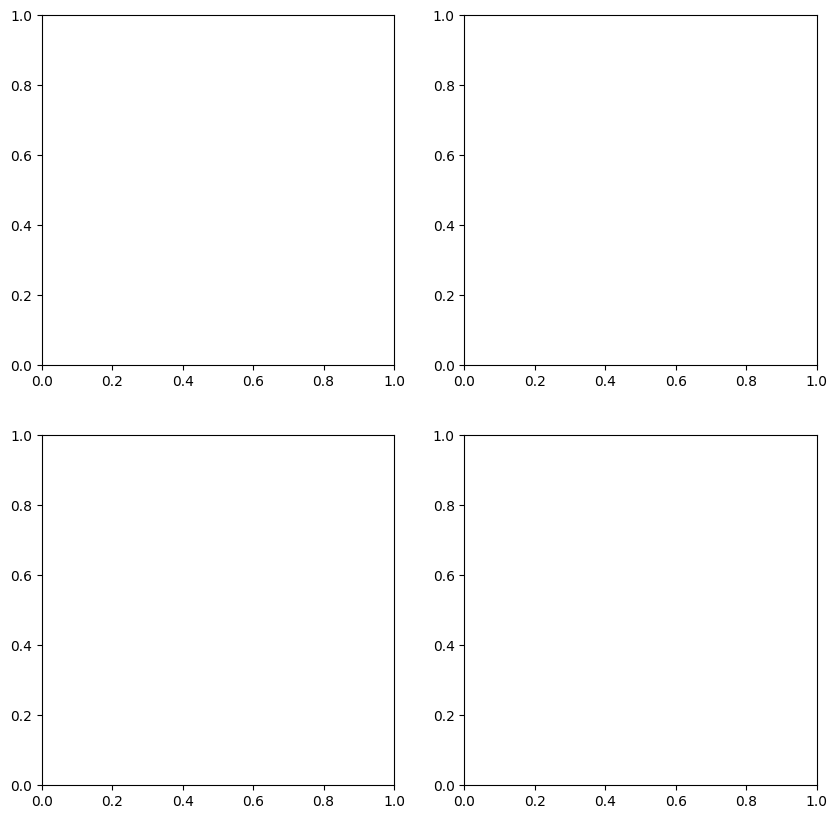

In [9]:
#mpl.use("Agg")
%matplotlib inline

var = 'leiden'

samples = list(adata_dict.keys())

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
slide = adata_dict[samples[0]]
sq.pl.spatial_scatter(slide, color=var, size=0, img_alpha=1, frameon=False, ax=axs[0, 0], legend_loc=None, crop_coord=crop_coord_1)
axs[0, 0].set_title('')
sq.pl.spatial_scatter(slide, color=var, size=1.4, img_alpha=0, frameon=False, ax=axs[0, 1],
crop_coord=crop_coord_1)
axs[0, 1].set_title('')

slide = adata_dict[samples[1]]
sq.pl.spatial_scatter(slide, color=var, size=0, img_alpha=1, frameon=False, ax=axs[1, 0], legend_loc=None, crop_coord=crop_coord_2)
axs[1, 0].set_title('')
sq.pl.spatial_scatter(slide, color=var, size=1.4, img_alpha=0, frameon=False, ax=axs[1, 1], crop_coord=crop_coord_2)
axs[1, 1].set_title('')

plt.tight_layout()
plt.subplots_adjust(hspace=-0.2)
#plt.savefig(f".../spatial_slide_and_clusters_focused_square_layout_{date}.pdf")
#plt.savefig(f".../spatial_slide_and_clusters_focused_square_layout_{date}.png")
plt.show()

### Figure 6D: CD93, IGFBP7, and MMRN2 expression across spots

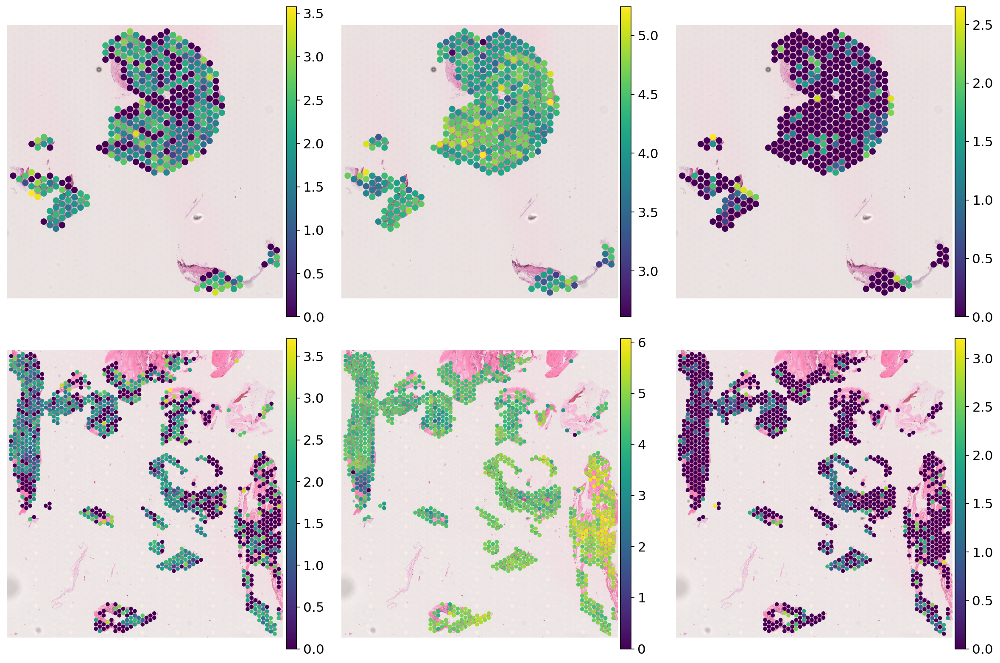

In [10]:
# FIgure 6D in bottom row

slide1 = norm_and_log(adata_dict[samples[0]])
slide2 = norm_and_log(adata_dict[samples[1]])

%matplotlib inline

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
sq.pl.spatial_scatter(slide1, color="CD93", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 0], legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
axs[0, 0].set_title('')
sq.pl.spatial_scatter(slide1, color="IGFBP7", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 1],
crop_coord=crop_coord_1, layer="log1p")
axs[0, 1].set_title('')
sq.pl.spatial_scatter(slide1, color="MMRN2", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 2], legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
axs[0, 2].set_title('')

sq.pl.spatial_scatter(slide2, color="CD93", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 0], legend_loc=None, crop_coord=crop_coord_2, layer="log1p")
axs[1, 0].set_title('')
sq.pl.spatial_scatter(slide2, color="IGFBP7", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 1],
crop_coord=crop_coord_2, layer="log1p")
axs[1, 1].set_title('')
sq.pl.spatial_scatter(slide2, color="MMRN2", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 2], legend_loc=None, crop_coord=crop_coord_2, layer="log1p")
axs[1, 2].set_title('')

plt.tight_layout()
#plt.savefig(f"..._{date}.pdf", bbox_inches="tight", dpi=300)
#plt.savefig(f"..._{date}.png", bbox_inches="tight", dpi=300)
plt.show()

### Figure 3B: oncofetal signature genes FOLR2, POSTN, and PLVAP expression across spots

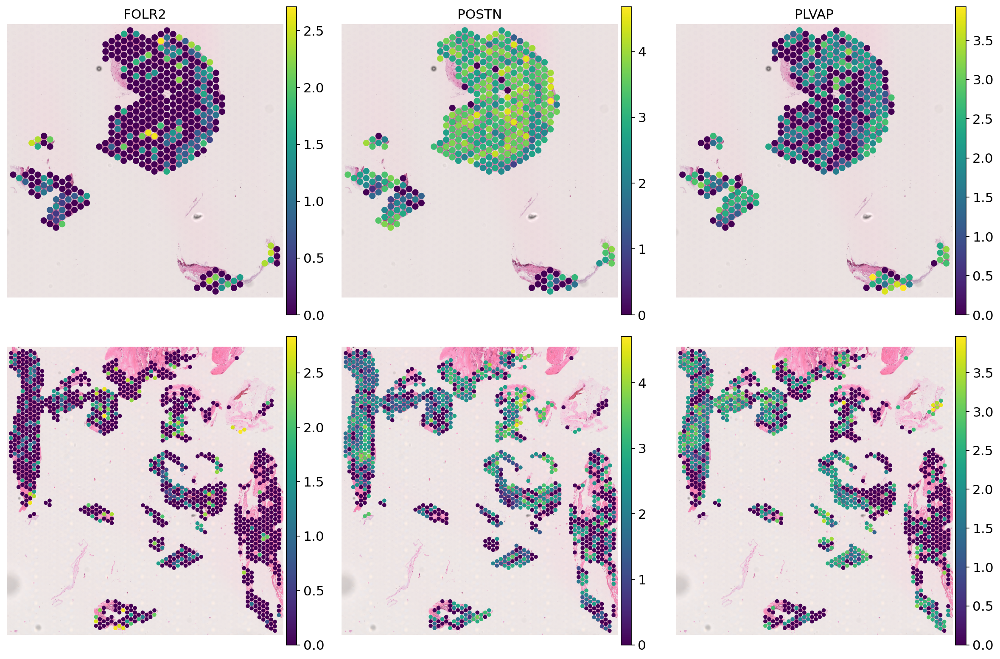

In [11]:


%matplotlib inline

fig, axs = plt.subplots(2, 3, figsize=(15, 10))
sq.pl.spatial_scatter(slide1, color="FOLR2", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 0], legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
axs[0, 0].set_title('FOLR2')
sq.pl.spatial_scatter(slide1, color="POSTN", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 1],
legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
axs[0, 1].set_title('POSTN')
sq.pl.spatial_scatter(slide1, color="PLVAP", size=1.4, img_alpha=1, frameon=False, ax=axs[0, 2], legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
axs[0, 2].set_title('PLVAP')
sq.pl.spatial_scatter(slide2, color="FOLR2", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 0], legend_loc=None, crop_coord=crop_coord_2, layer="log1p")
axs[1, 0].set_title('')
sq.pl.spatial_scatter(slide2, color="POSTN", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 1],
legend_loc=None, crop_coord=crop_coord_2, layer="log1p")
axs[1, 1].set_title('')
sq.pl.spatial_scatter(slide2, color="PLVAP", size=1.4, img_alpha=1, frameon=False, ax=axs[1, 2], legend_loc=None, crop_coord=crop_coord_2, layer="log1p")
axs[1, 2].set_title('')

plt.tight_layout()
#plt.savefig(f"..._{date}.pdf", bbox_inches="tight", dpi=300)
#plt.savefig(f"..._{date}.png", bbox_inches="tight", dpi=300)
plt.show()

In [23]:
# Convenience function for variable spatial gene expression plots
def print_spatial_gene_expression(
    genes,
    save=False,
    gene_title=True
):
    %matplotlib inline
    if save:
        mpl.use("Agg")

    n = len(genes)
    gene_str = ("_").join(genes)

    fig, axs = plt.subplots(2, n, figsize=(n*5, 10))

    for idx, gene in enumerate(genes):
        sq.pl.spatial_scatter(slide1, color=gene, size=1.4, img_alpha=1, frameon=False, ax=axs[0, idx], legend_loc=None, crop_coord=crop_coord_1, layer="log1p")
        axs[0, idx].set_title(gene)
        if not gene_title:
            axs[0, idx].set_title("")
        sq.pl.spatial_scatter(slide2, color=gene, size=1.4, img_alpha=1, frameon=False, ax=axs[1, idx], legend_loc=None, crop_coord=crop_coord_2, layer="log1p", title="")

    """if save:
        plt.savefig(f"..._{gene_str}_{date}.pdf", bbox_inches='tight', dpi=300)
        plt.savefig(f"..._{gene_str}_{date}.png", bbox_inches='tight', dpi=300)"""

### Supplementary figure S6C

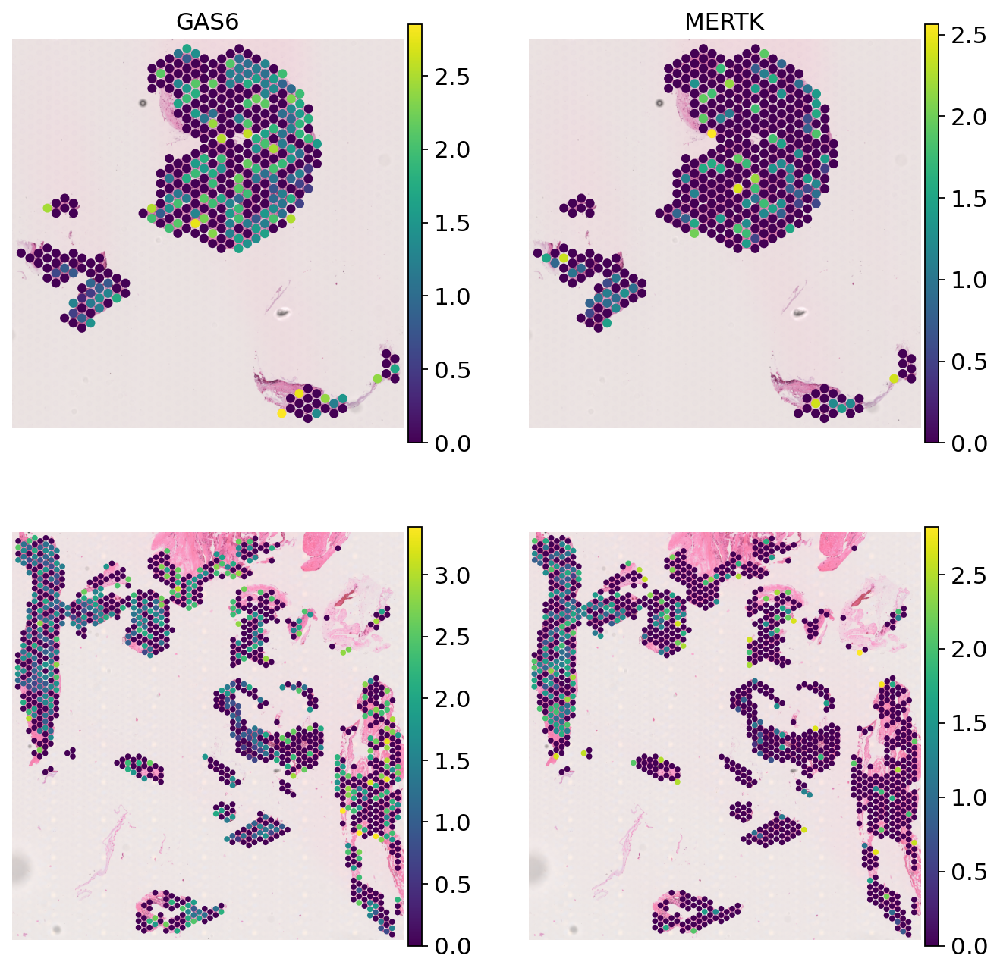

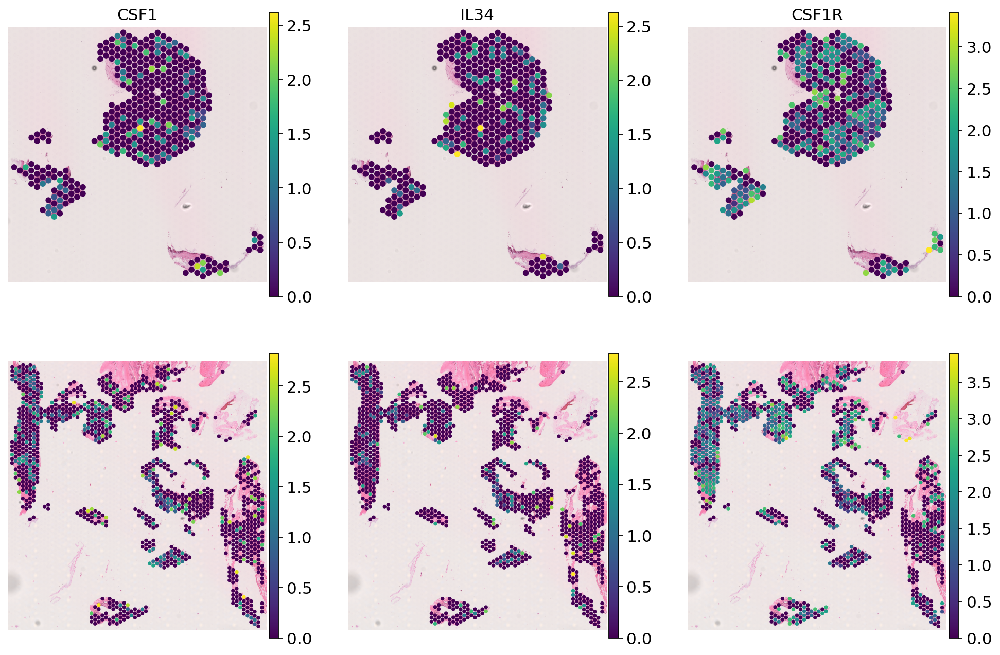

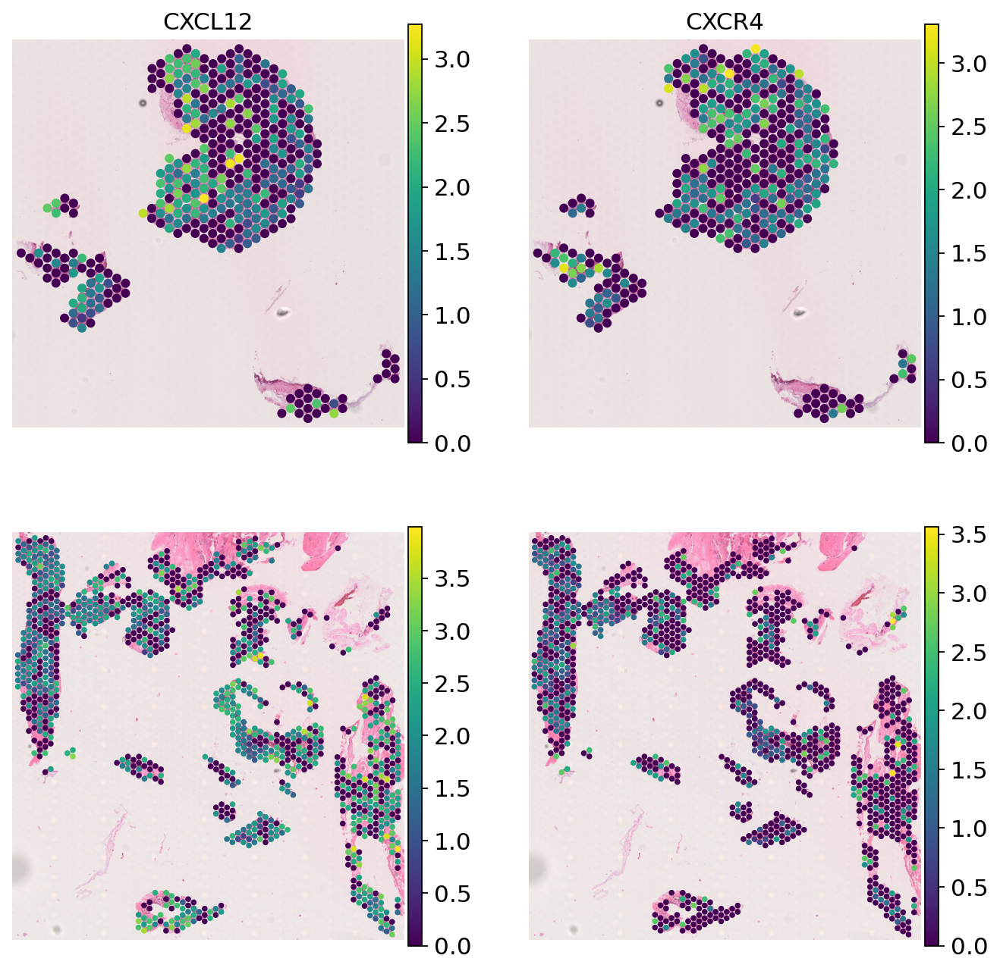

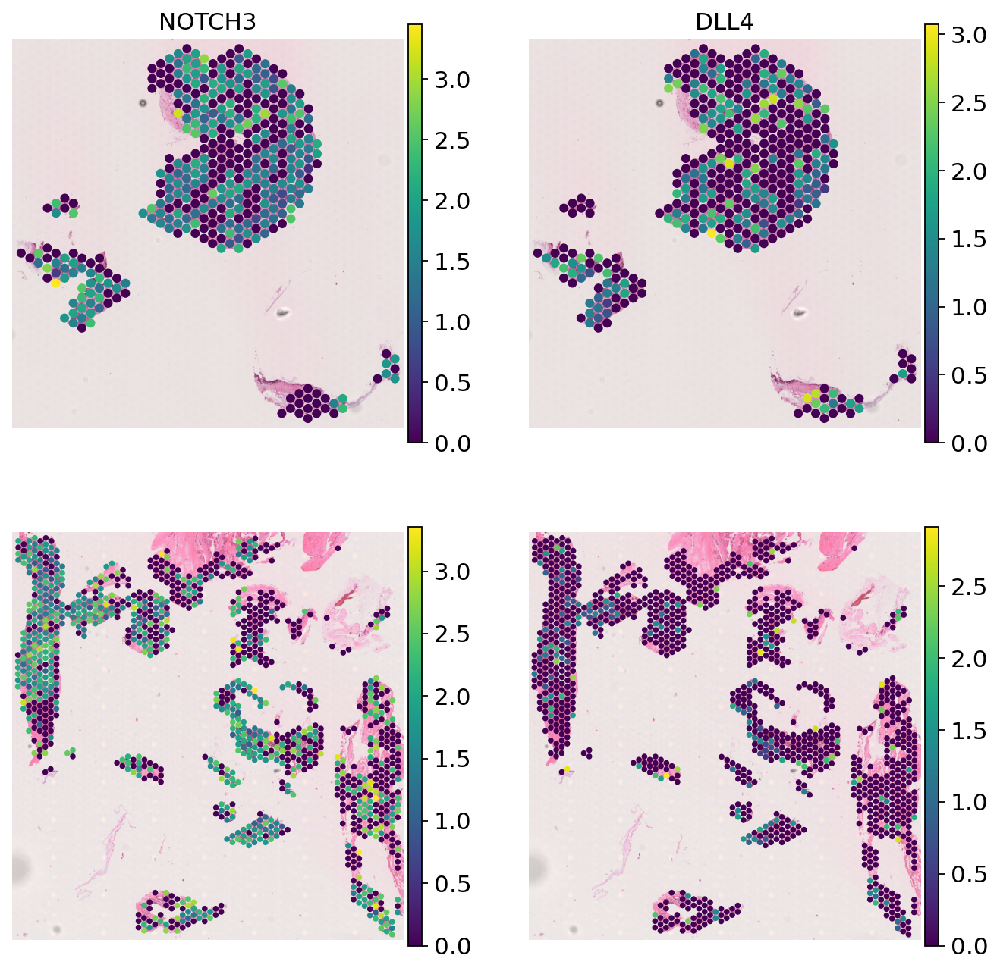

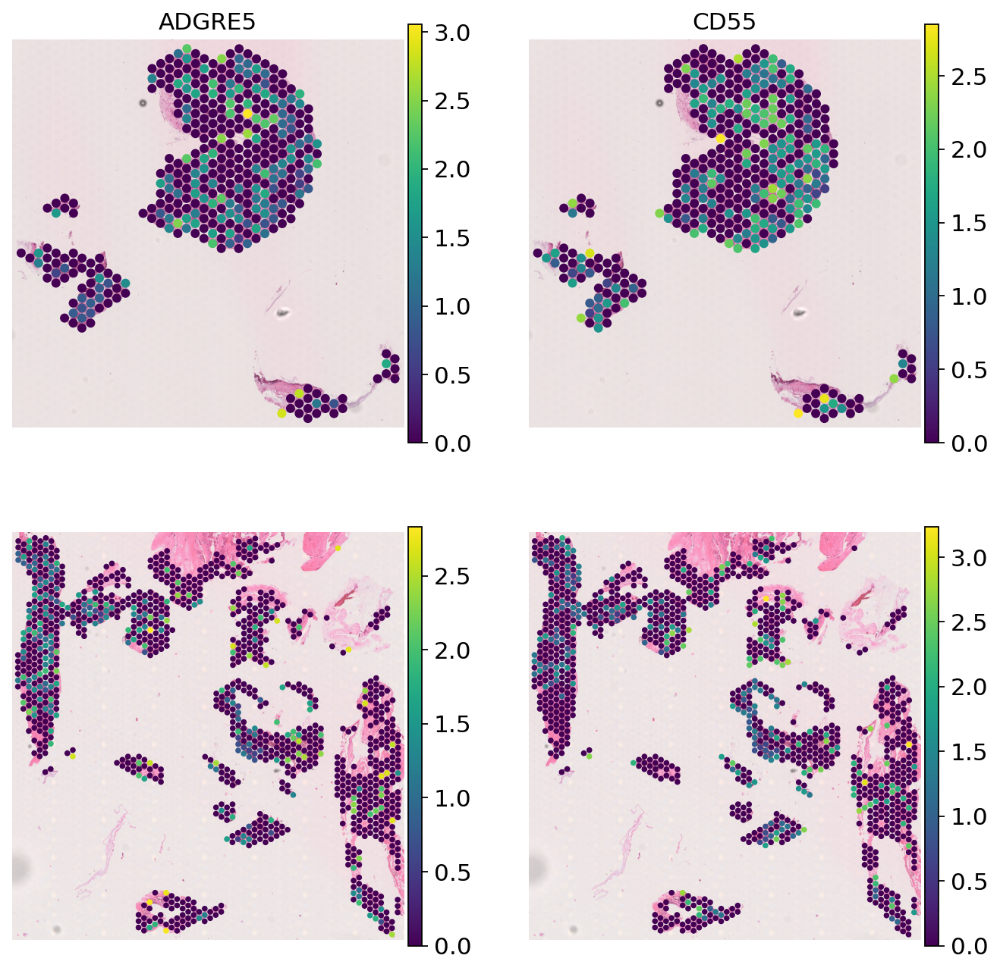

In [16]:
# Only the first row was used
print_spatial_gene_expression(genes=["GAS6", "MERTK"], gene_title=True, save=False)
print_spatial_gene_expression(genes=["CSF1", "IL34", "CSF1R"], gene_title=True, save=False)
print_spatial_gene_expression(genes=["CXCL12", "CXCR4"], gene_title=True, save=False)
print_spatial_gene_expression(genes=["NOTCH3", "DLL4"], gene_title=True, save=False)
print_spatial_gene_expression(genes=["ADGRE5", "CD55"], gene_title=True, save=False)

### Figure 1A

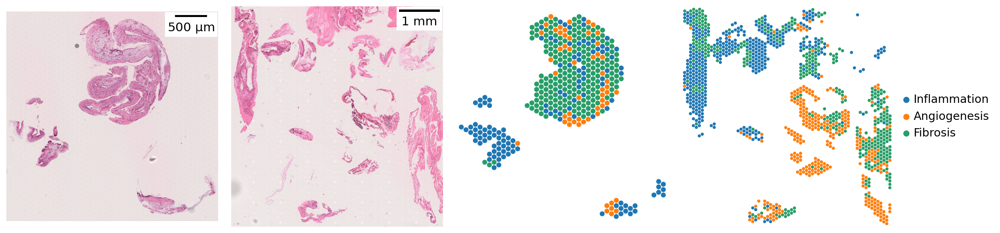

In [17]:
# One continuous strip format
# Further box outlines were added outside of code

#mpl.use("Agg")
%matplotlib inline

SPOT_DIAMETER_µm = 55
hires_scalef_1 = adata_dict[samples[0]].uns["spatial"][samples[0]]["scalefactors"]["tissue_hires_scalef"]
hires_scalef_2 = adata_dict[samples[1]].uns["spatial"][samples[1]]["scalefactors"]["tissue_hires_scalef"]
spot_d_1 = adata_dict[samples[0]].uns["spatial"][samples[0]]["scalefactors"]["spot_diameter_fullres"]
spot_d_2 = adata_dict[samples[1]].uns["spatial"][samples[1]]["scalefactors"]["spot_diameter_fullres"]

var = 'cluster'

samples = list(adata_dict.keys())

fig, axs = plt.subplots(1, 4, figsize=(16, 4))
slide = adata_dict[samples[0]]
sq.pl.spatial_scatter(slide, color=var, size=0, img_alpha=1, frameon=False, ax=axs[0], legend_loc=None, crop_coord=crop_coord_1, scalebar_dx=(SPOT_DIAMETER_µm / spot_d_1 / hires_scalef_1))
axs[0].set_title('')
sq.pl.spatial_scatter(slide, color=var, size=1.4, img_alpha=0, frameon=False, ax=axs[2],
crop_coord=crop_coord_1, legend_loc=None)
axs[2].set_title('')

slide = adata_dict[samples[1]]
sq.pl.spatial_scatter(slide, color=var, size=0, img_alpha=1, frameon=False, ax=axs[1], legend_loc=None, crop_coord=crop_coord_2, scalebar_dx=(SPOT_DIAMETER_µm / spot_d_2 / hires_scalef_2))
axs[1].set_title('')
sq.pl.spatial_scatter(slide, color=var, size=1.4, img_alpha=0, frameon=False, ax=axs[3], crop_coord=crop_coord_2)
axs[3].set_title('')

plt.tight_layout()
#plt.savefig(f"..._{date}.pdf", bbox_inches="tight", dpi=300)
#plt.savefig(f"..._{date}.png", bbox_inches="tight", dpi=300)
plt.show()

### Figure 1B

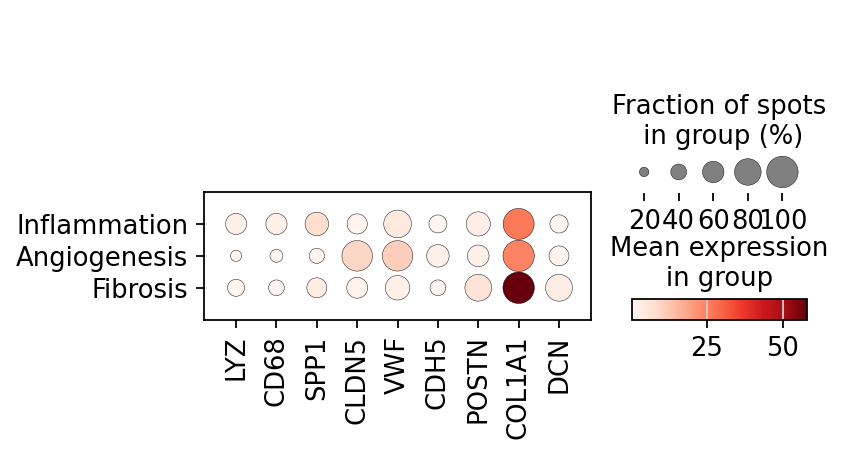

In [25]:
#mpl.use("Agg")
%matplotlib inline

# Marker genes 
marker_genes = [
    "LYZ", "CD68", "SPP1", # Inflammation
    "CLDN5", "VWF", "CDH5", # Angiogenesis
    "POSTN", # Fibrosis
    "COL1A1", "DCN"
]

sc.pl.dotplot(
    adata_concat,
    marker_genes,
    groupby='cluster',
    size_title="Fraction of spots\n in group (%)"
)

#plt.savefig(f"..._{date}.pdf", bbox_inches="tight", dpi=300)
#plt.savefig(f"..._{date}.png", bbox_inches="tight", dpi=300)
plt.show()

### Figure 6C

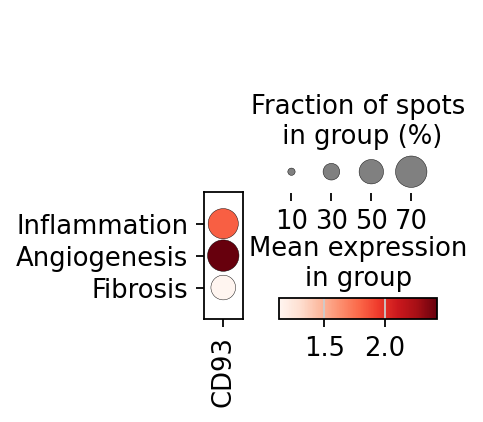

<Figure size 480x480 with 0 Axes>

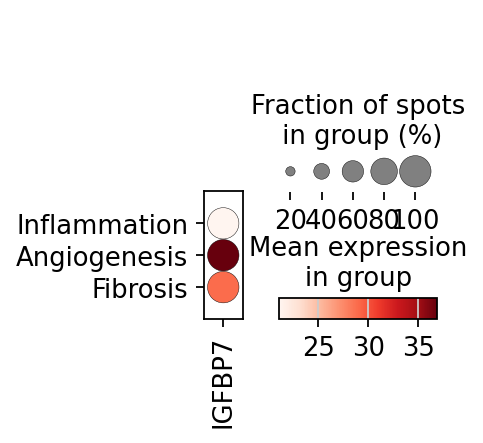

<Figure size 480x480 with 0 Axes>

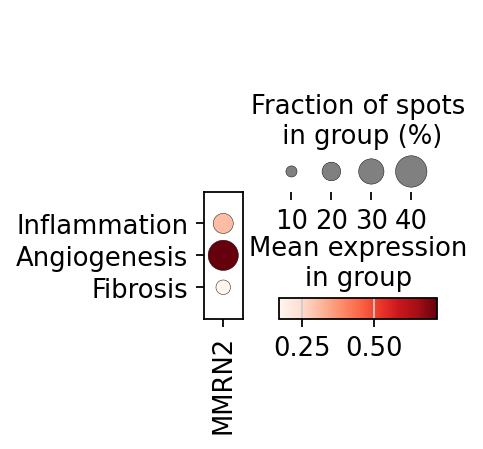

<Figure size 480x480 with 0 Axes>

In [32]:
#mpl.use("Agg")
%matplotlib inline

# Marker genes 
marker_genes = [
    "CD93", "IGFBP7", "MMRN2" 
]

for gene in marker_genes:

    sc.pl.dotplot(
        adata_concat,
        gene,
        groupby='cluster',
        size_title="Fraction of spots\n in group (%)"
    )

    plt.tight_layout()
    #plt.savefig(f"..._{gene}_{date}.pdf", bbox_inches="tight", dpi=300)
    #plt.savefig(f"..._{gene}_{date}.png", bbox_inches="tight", dpi=300)
    plt.show()